In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# Cell 1: Verifikasi GPU dan Install Library yang Dibutuhkan
import torch

print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device Name:", torch.cuda.get_device_name(0))

# Install timm (Pytorch Image Models) untuk akses Vision Transformer
!pip install -q timm albumentations scikit-learn matplotlib

GPU Available: True
Device Name: Tesla T4


In [3]:
# Cell 2 (Opsi A): Unzip file dataset yang di-upload ke Colab
import zipfile
import os

zip_path = '/content/drive/MyDrive/Colab Notebooks/paddy-disease-classification.zip' # Sesuaikan nama file zip kamu

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('paddy_data')
    print("Unzip selesai!")
else:
    print("File zip tidak ditemukan! Upload dulu ke panel kiri Colab.")

Unzip selesai!


In [4]:
# Cell 3: Data Pipeline & DataLoaders
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import transforms, datasets

# Path folder train_images hasil extract
data_dir = 'paddy_data/train_images'

# Transformasi & Augmentasi khusus input Vision Transformer
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load dataset utama
full_dataset = datasets.ImageFolder(root=data_dir)
class_names = full_dataset.classes
print(f"Total gambar ditemukan: {len(full_dataset)}")
print(f"Jumlah kelas ({len(class_names)}): {class_names}")

# Pembagian data 80% Train, 20% Val
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size

train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

# Terapkan transformasi
train_dataset.dataset.transform = train_transform
val_dataset.dataset.transform = val_transform

# DataLoader
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

print(f"Data Train: {len(train_dataset)} | Data Val: {len(val_dataset)}")

Total gambar ditemukan: 10407
Jumlah kelas (10): ['bacterial_leaf_blight', 'bacterial_leaf_streak', 'bacterial_panicle_blight', 'blast', 'brown_spot', 'dead_heart', 'downy_mildew', 'hispa', 'normal', 'tungro']
Data Train: 8325 | Data Val: 2082


In [5]:
# Cell 4: Load Arsitektur ViT
import timm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Membuat model ViT dengan jumlah output kelas sesuai dataset padi
model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=len(class_names))
model = model.to(device)

# Loss Function & Optimizer (AdamW adalah standar terbaik untuk ViT)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=0.01)

print("Model ViT berhasil dimuat ke:", device)

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Model ViT berhasil dimuat ke: cuda


In [6]:
# Cell 5: Training Loop
import time

epochs = 5  # Kamu bisa ubah ke 10 atau lebih nanti

print("Mulai Proses Training ViT...\n" + "="*40)

for epoch in range(epochs):
    start_time = time.time()

    # --- TRAINING PHASE ---
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += torch.sum(preds == labels.data)
        total_train += labels.size(0)

    train_loss = running_loss / total_train
    train_acc = correct_train.double() / total_train

    # --- VALIDATION PHASE ---
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_val += torch.sum(preds == labels.data)
            total_val += labels.size(0)

    val_loss = val_loss / total_val
    val_acc = correct_val.double() / total_val

    elapsed = time.strftime("%H:%M:%S", time.gmtime(time.time() - start_time))

    print(f"Epoch [{epoch+1}/{epochs}] | Waktu: {elapsed}")
    print(f"  Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}%")
    print(f"  Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc*100:.2f}%\n")

Mulai Proses Training ViT...
Epoch [1/5] | Waktu: 00:05:54
  Train Loss: 0.9531 | Train Acc: 67.87%
  Val Loss:   0.5795 | Val Acc:   80.64%

Epoch [2/5] | Waktu: 00:06:03
  Train Loss: 0.3107 | Train Acc: 89.90%
  Val Loss:   0.3149 | Val Acc:   90.30%

Epoch [3/5] | Waktu: 00:06:02
  Train Loss: 0.1828 | Train Acc: 93.91%
  Val Loss:   0.2385 | Val Acc:   92.12%

Epoch [4/5] | Waktu: 00:06:02
  Train Loss: 0.1034 | Train Acc: 96.71%
  Val Loss:   0.2294 | Val Acc:   92.60%

Epoch [5/5] | Waktu: 00:06:02
  Train Loss: 0.0947 | Train Acc: 96.83%
  Val Loss:   0.3735 | Val Acc:   88.76%



In [7]:
# Cell 6: Simpan Model Weights
torch.save(model.state_dict(), 'vit_paddy_model.pth')
print("Model berhasil disimpan sebagai 'vit_paddy_model.pth'!")

Model berhasil disimpan sebagai 'vit_paddy_model.pth'!


=== CLASSIFICATION REPORT ===
                          precision    recall  f1-score   support

   bacterial_leaf_blight       0.94      0.54      0.68        93
   bacterial_leaf_streak       0.98      0.96      0.97        85
bacterial_panicle_blight       0.92      0.86      0.88        76
                   blast       0.94      0.83      0.88       343
              brown_spot       0.73      0.93      0.82       182
              dead_heart       0.86      0.99      0.92       280
            downy_mildew       0.81      0.88      0.85       138
                   hispa       0.95      0.82      0.88       317
                  normal       0.92      0.96      0.94       358
                  tungro       0.89      0.92      0.91       210

                accuracy                           0.89      2082
               macro avg       0.89      0.87      0.87      2082
            weighted avg       0.90      0.89      0.89      2082



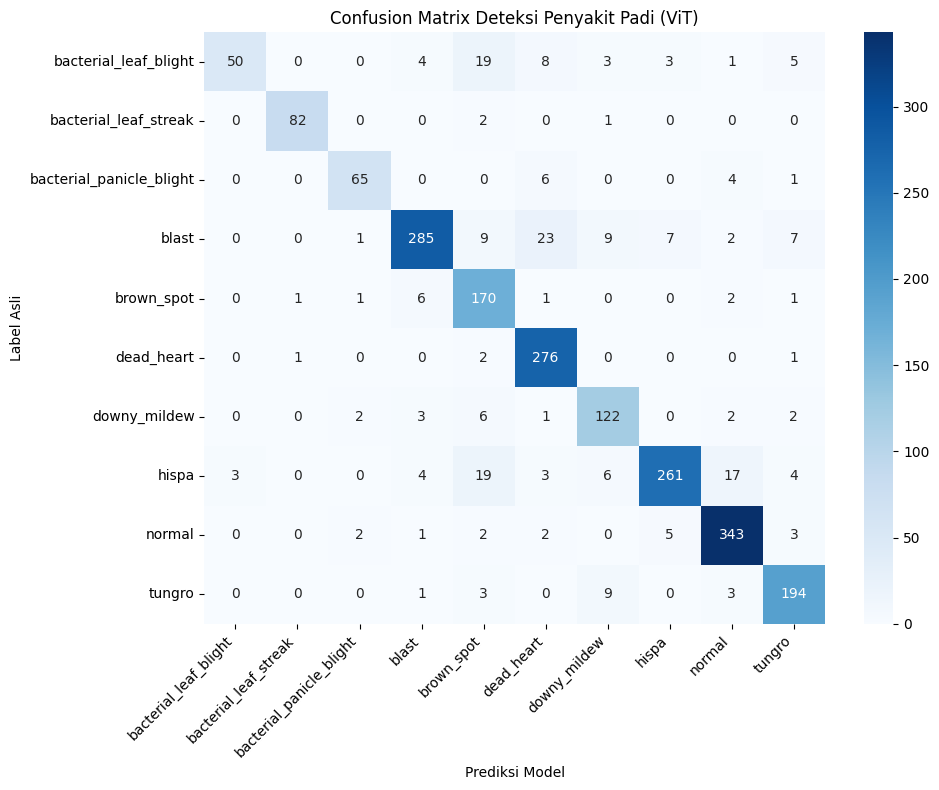

In [8]:
# Cell 7: Generate Metric Laporan
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# 1. Print Classification Report (Precision, Recall, F1-Score)
print("=== CLASSIFICATION REPORT ===")
print(classification_report(all_labels, all_preds, target_names=class_names))

# 2. Plot Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Prediksi Model')
plt.ylabel('Label Asli')
plt.title('Confusion Matrix Deteksi Penyakit Padi (ViT)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Upload satu gambar daun padi untuk dites...


Saving 201647.jpg to 201647.jpg


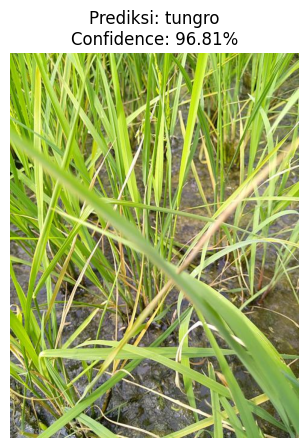

In [10]:
# Cell 8: Tes Prediksi Gambar Baru
from PIL import Image
from google.colab import files

print("Upload satu gambar daun padi untuk dites...")
uploaded = files.upload()

for filename in uploaded.keys():
    # Load & Preprocess Gambar
    raw_img = Image.open(filename).convert('RGB')
    input_tensor = val_transform(raw_img).unsqueeze(0).to(device)

    # Prediksi
    model.eval()
    with torch.no_grad():
        output = model(input_tensor)
        probabilities = torch.nn.functional.softmax(output[0], dim=0)

    top_prob, top_catid = torch.topk(probabilities, 1)
    predicted_class = class_names[top_catid[0].item()]
    confidence = top_prob[0].item() * 100

    # Tampilkan Gambar & Hasil
    plt.figure(figsize=(5, 5))
    plt.imshow(raw_img)
    plt.title(f"Prediksi: {predicted_class}\nConfidence: {confidence:.2f}%")
    plt.axis('off')
    plt.show()

In [11]:
# Cell 9: Visualisasi Attention Map pada Gambar
import cv2
import numpy as np
import matplotlib.pyplot as plt

def generate_attention_map(model, input_tensor):
    model.eval()
    # Mengambil bobot attention dari layer Transformer terakhir
    # Pada ViT timm, biasanya tersimpan di blok terakhir
    attention_maps = []

    def hook_fn(module, input, output):
        # Mengambil matriks attention
        attention_maps.append(output)

    # Pasang hook pada layer attention terakhir
    target_layer = model.blocks[-1].attn
    handle = target_layer.register_forward_hook(hook_fn)

    with torch.no_grad():
        _ = model(input_tensor)

    handle.remove()
    return attention_maps

print("Siap! Kamu bisa pakai modul visualisasi ini untuk menganalisis area fokus ViT pada daun padi.")

Siap! Kamu bisa pakai modul visualisasi ini untuk menganalisis area fokus ViT pada daun padi.


Upload 1 gambar daun padi untuk melihat area fokus ViT...


Saving 203409.jpg to 203409.jpg


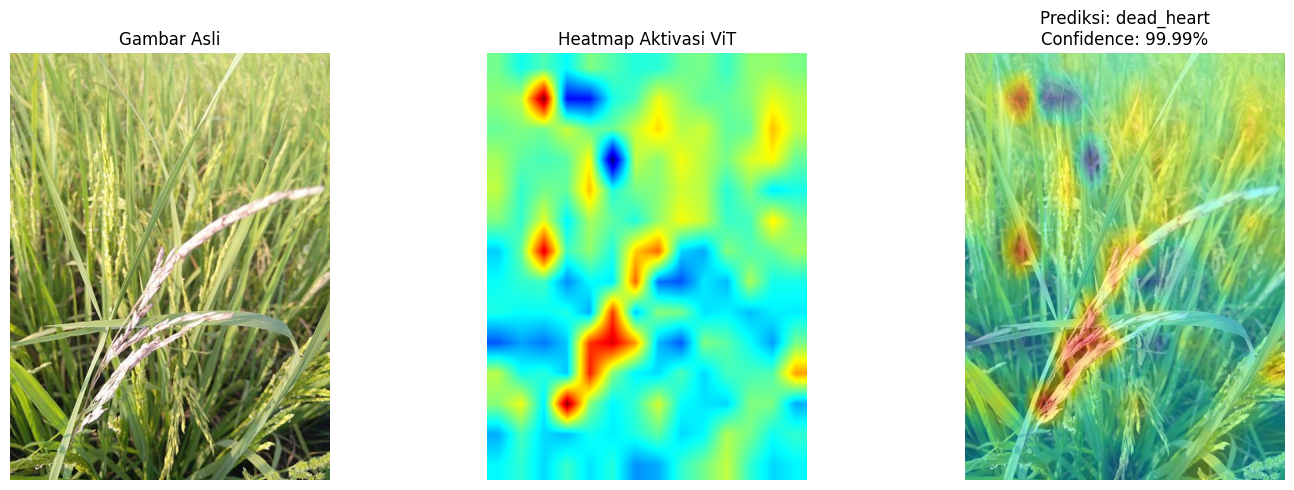

In [15]:
# Cell 10 (Fixed Total): Visualisasi Heatmap Aktivasi ViT
from PIL import Image
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Upload 1 gambar daun padi untuk melihat area fokus ViT...")
uploaded = files.upload()

for filename in uploaded.keys():
    # 1. Load & Preprocess Gambar
    raw_img = Image.open(filename).convert('RGB')
    orig_img = np.array(raw_img)

    input_tensor = val_transform(raw_img).unsqueeze(0).to(device)

    # 2. Forward Pass & Ambil Feature Map dari Layer Terakhir
    features = []
    def hook_fn(module, input, output):
        features.append(output)

    handle = model.blocks[-1].register_forward_hook(hook_fn)

    model.eval()
    with torch.no_grad():
        output = model(input_tensor)
        probabilities = torch.nn.functional.softmax(output[0], dim=0)

    handle.remove()

    # 3. Prediksi
    top_prob, top_catid = torch.topk(probabilities, 1)
    pred_label = class_names[top_catid[0].item()]
    conf = top_prob[0].item() * 100

    # 4. Ekstrak Heatmap dari Feature Map (14x14 Patch Grid)
    feat = features[0] # Shape: [1, 197, 768]

    # Ambil token patch (abaikan token [CLS] di index 0) -> Shape: [196, 768]
    patch_feat = feat[0, 1:, :]

    # Rata-rata kekuatan aktivasi di sepanjang channel (768) -> Shape: [196]
    heatmap_1d = patch_feat.abs().mean(dim=-1).cpu().numpy()

    # Reshape persis ke grid 14x14
    heatmap = heatmap_1d.reshape(14, 14)

    # Normalisasi nilai (0 sampai 1)
    heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)

    # Resize Heatmap ke ukuran gambar asli
    heatmap_resized = cv2.resize(heatmap, (orig_img.shape[1], orig_img.shape[0]))

    # Warna Heatmap (Colormap JET: Merah = Fokus Tinggi, Biru = Rendah)
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)

    # Combine (Overlay) Gambar + Heatmap
    overlay = cv2.addWeighted(orig_img, 0.6, heatmap_colored, 0.4, 0)

    # 5. Tampilkan Gambar
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(orig_img)
    axes[0].set_title("Gambar Asli")
    axes[0].axis('off')

    axes[1].imshow(heatmap_colored)
    axes[1].set_title("Heatmap Aktivasi ViT")
    axes[1].axis('off')

    axes[2].imshow(overlay)
    axes[2].set_title(f"Prediksi: {pred_label}\nConfidence: {conf:.2f}%")
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()